In [81]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import MinMaxScaler, LabelEncoder, StandardScaler, RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report,precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.tree import DecisionTreeClassifier
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.3f' % x)
pd.set_option('display.width', 500)
import warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot  as plt
from sklearn import preprocessing
np.random.seed(0)

In [82]:
loans = pd.read_csv('Loans_Dataset.csv')
loans

,initial_payment,last_payment,credit_score,house_number,sum,result
0,201,10018,250,3046,13515,yes
1,205,10016,395,3044,13660,yes
2,257,10129,109,3251,13746,yes
3,246,10064,324,3137,13771,yes
4,117,10115,496,3094,13822,yes
...,...,...,...,...,...,...
999,168,14798,834,4937,20737,No
1000,234,14567,756,4766,20678,yes
1001,450,13897,867,7896,210456,yes
1002,347,14999,687,9876,246789,yes


In [83]:
loans.drop('house_number', axis=1, inplace=True)
loans

,initial_payment,last_payment,credit_score,sum,result
0,201,10018,250,13515,yes
1,205,10016,395,13660,yes
2,257,10129,109,13746,yes
3,246,10064,324,13771,yes
4,117,10115,496,13822,yes
...,...,...,...,...,...
999,168,14798,834,20737,No
1000,234,14567,756,20678,yes
1001,450,13897,867,210456,yes
1002,347,14999,687,246789,yes


In [84]:
loans.shape

(1004, 5)

In [85]:
loans.describe

<bound method NDFrame.describe of       initial_payment  last_payment  credit_score     sum result
0                 201         10018           250   13515    yes
1                 205         10016           395   13660    yes
2                 257         10129           109   13746    yes
3                 246         10064           324   13771    yes
4                 117         10115           496   13822    yes
...               ...           ...           ...     ...    ...
999               168         14798           834   20737     No
1000              234         14567           756   20678    yes
1001              450         13897           867  210456    yes
1002              347         14999           687  246789    yes
1003              467         13555           666   21786    yes

[1004 rows x 5 columns]>

In [86]:
loans.isnull().values.any()

np.False_

In [87]:
features = loans.drop('result', axis=1)
features

,initial_payment,last_payment,credit_score,sum
0,201,10018,250,13515
1,205,10016,395,13660
2,257,10129,109,13746
3,246,10064,324,13771
4,117,10115,496,13822
...,...,...,...,...
999,168,14798,834,20737
1000,234,14567,756,20678
1001,450,13897,867,210456
1002,347,14999,687,246789


In [88]:
y = loans['result']
y

0       yes
1       yes
2       yes
3       yes
4       yes
       ... 
999      No
1000    yes
1001    yes
1002    yes
1003    yes
Name: result, Length: 1004, dtype: str

<Axes: xlabel='credit_score', ylabel='result'>

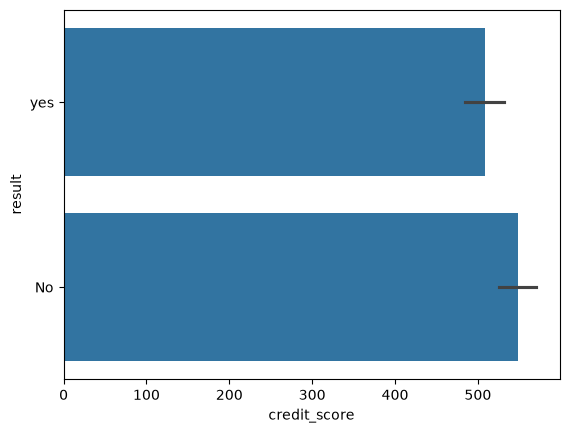

In [89]:
sns.barplot(loans, x='credit_score', y='result')

<Axes: >

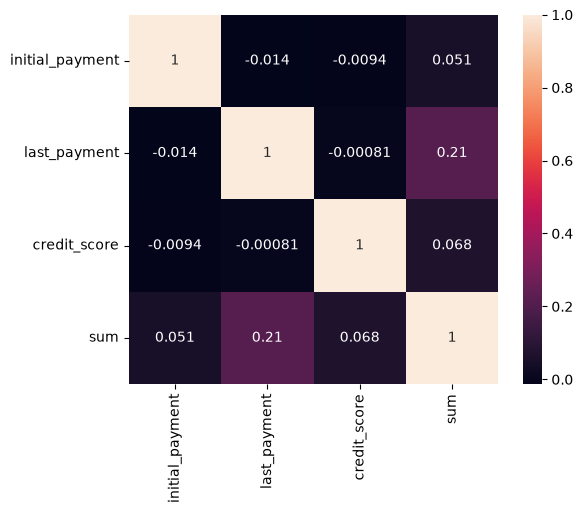

In [90]:
corrmat = loans.select_dtypes(include='number').corr()

sns.heatmap(corrmat, annot = True, square = True)

In [91]:
scaler = StandardScaler()
x = scaler.fit_transform(features)
x

array([[-0.80892281, -1.70319339, -1.07455143, -0.44098704],
       [-0.77437647, -1.70458091, -0.51589735, -0.42586694],
       [-0.32527407, -1.62618577, -1.61779436, -0.41689915],
       ...,
       [ 1.34158674,  0.98791062,  1.30261798, 20.09534852],
       [ 0.45201853,  1.75243669,  0.60911637, 23.8840298 ],
       [ 1.48840867,  0.75064391,  0.52820785,  0.42148462]],
      shape=(1004, 4))

In [92]:
pd.DataFrame(features).describe()

,initial_payment,last_payment,credit_score,sum
count,1004.000,1004.000,1004.000,1004.000
mean,294.662,12473.010,528.902,17744.013
std,115.844,1442.134,259.682,9594.660
min,100.000,10005.000,100.000,13515.000
25%,195.750,11213.500,302.750,16081.250
50%,290.000,12467.000,518.000,17383.000
75%,398.000,13690.000,755.000,18608.250
max,500.000,14999.000,997.000,246789.000


In [93]:
labels.value_counts()

result
No     521
yes    483
Name: count, dtype: int64

In [94]:
xtrain, xtest, ytrain, ytest = train_test_split(x,y,train_size=0.8,random_state=7)

In [95]:
ytrain.value_counts()

result
No     407
yes    396
Name: count, dtype: int64

In [96]:
x.shape

(1004, 4)

In [99]:
dt = DecisionTreeClassifier(ccp_alpha=0.0, class_weight=None, criterion='gini',
                       max_depth=None, max_features=None, max_leaf_nodes=None,
                       min_impurity_decrease=0.0, 
                       min_samples_leaf=1, min_samples_split=2,
                       min_weight_fraction_leaf=0.0, 
                       random_state=None, splitter='best')
dt.fit(xtrain, ytrain)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [100]:
print(dt.score(xtrain, ytrain))  
print(dt.get_depth()) 

1.0
4


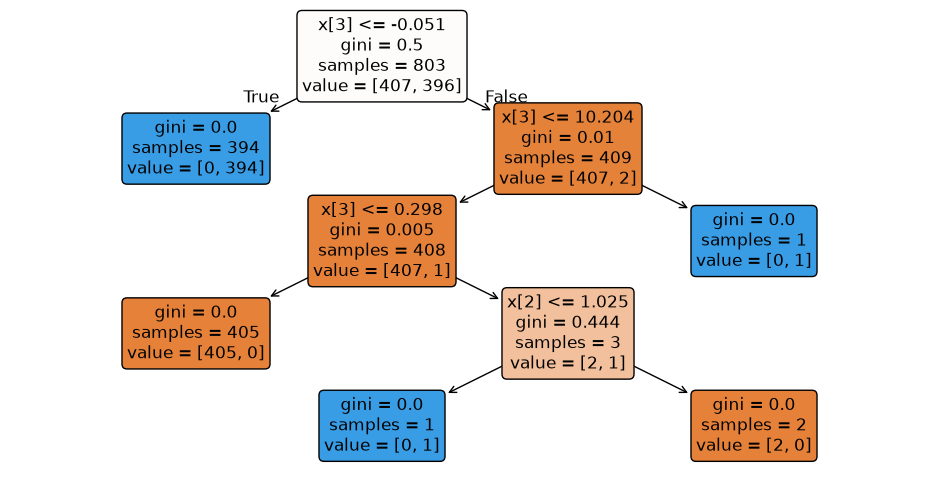

In [102]:
def display_tree(dt):
    from sklearn.tree import plot_tree
    plt.figure(figsize=(12, 6))
    plot_tree(dt, filled=True, rounded=True, precision=3)
    plt.show()
    
display_tree(dt)

In [103]:
ypred= dt.predict(xtest)
print(f"Accuracy : {accuracy_score(ytest,ypred):.4f}")
print(f"Precision : {precision_score(ytest,ypred,pos_label='yes'):.4f}")
print(f"Recall : {recall_score(ytest,ypred,pos_label='yes'):.4f}")
print(f"F1 Score : {f1_score(ytest,ypred,pos_label='yes'):.4f}")

Accuracy : 1.0000
Precision : 1.0000
Recall : 1.0000
F1 Score : 1.0000


<Axes: >

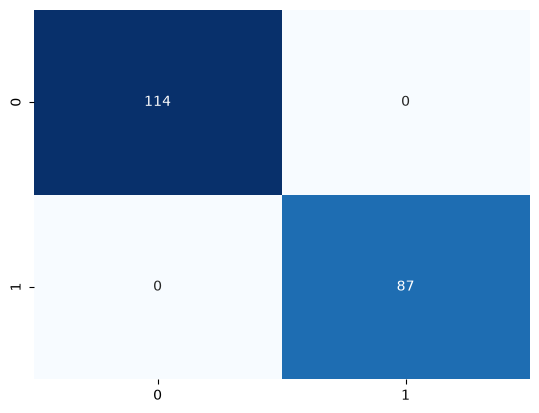

In [104]:
cf_matrix = confusion_matrix(ytest, ypred)
sns.heatmap(cf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False)

In [105]:
print("\nClassification Report:")
print(classification_report(
    ytest,
    ypred,
    target_names=["Loan paid", "Loan not paid"]
))


Classification Report:
               precision    recall  f1-score   support

    Loan paid       1.00      1.00      1.00       114
Loan not paid       1.00      1.00      1.00        87

     accuracy                           1.00       201
    macro avg       1.00      1.00      1.00       201
 weighted avg       1.00      1.00      1.00       201

